# Driver Behaviour Recognition from Smartphone Motion Sensors
### Pattern Recognition (MOOC-Based) — CCA 1: Case-Study-Based Problem Solving

**Problem.** Aggressive manoeuvres (harsh braking, hard acceleration, sharp turns, abrupt lane changes) are a leading cause of road accidents. Insurers (usage-based insurance), fleet operators and road-safety apps need to **recognise these driving events automatically** from cheap sensors. A smartphone fixed in the car already carries an accelerometer, gyroscope and magnetometer, so the task becomes a **multi-class time-series pattern recognition problem**:

> Given a short window of 12-channel motion-sensor data, decide which of 7 driving events it belongs to.

**Dataset.** *Driver Behavior Dataset* (Ferreira Júnior et al., PLOS ONE, 2017). It was recorded in a 2011 Honda Civic with a windshield-mounted Android phone over 4 trips (~13 min each), with 69 video-labelled events in 7 classes. Public at `github.com/jair-jr/driverBehaviorDataset`.

**Three solutions compared**

| # | Approach | Paradigm |
|---|---|---|
| 1 | Statistical time-domain features + **Mutual Information feature selection** + **SVM (RBF kernel)** | Filter feature selection + margin-based classifier |
| 2 | Same features + **Random Forest with embedded (Gini-importance) feature selection** | Embedded feature selection + tree ensemble |
| 3 | Raw sequences + **Bidirectional LSTM** | Deep learning; learns its own features (implicit selection) |

**Group members:** Harshit Seth · Member 2 · Member 3 · Member 4

## 0. Setup
Runs as-is on Google Colab or any machine with Python 3.9+. All required libraries are pre-installed on Colab.

In [1]:
import os, json, time, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, SelectFromModel, mutual_info_classif
from functools import partial
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, roc_curve, auc, roc_auc_score)
import torch, torch.nn as nn

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

DATA_DIR, FIG_DIR = 'driver_data', 'figures'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# Plot style: thin marks, recessive grid, one fixed colour per model
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
                     'font.family': 'DejaVu Sans'})
MODEL_COLORS = {'SVM': '#2a78d6', 'Random Forest': '#eb6834', 'BiLSTM': '#1baf7a'}
INK, INK2 = '#0b0b0b', '#52514e'

def savefig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()

## 1. Data acquisition
Each trip folder holds four sensor CSVs (earth-frame x/y/z), a `groundTruth.csv` with event start/end times, and `viagem.json` with trip metadata.

In [2]:
BASE = 'https://raw.githubusercontent.com/jair-jr/driverBehaviorDataset/master/data'
TRIPS = ['16', '17', '20', '21']
SENSORS = {'Accelerometer': 'acelerometro_terra', 'Linear acc.': 'aceleracaoLinear_terra',
           'Gyroscope': 'giroscopio_terra', 'Magnetometer': 'campoMagnetico_terra'}
FILES = [f + '.csv' for f in SENSORS.values()] + ['groundTruth.csv', 'viagem.json']

for trip in TRIPS:
    os.makedirs(f'{DATA_DIR}/{trip}', exist_ok=True)
    for f in FILES:
        path = f'{DATA_DIR}/{trip}/{f}'
        if not os.path.exists(path):
            urllib.request.urlretrieve(f'{BASE}/{trip}/{f}', path)
print('Downloaded:', sorted(os.listdir(DATA_DIR)))

# Original Portuguese labels -> English class names
LABELS = {'evento_nao_agressivo': 'Non-aggressive',
          'aceleracao_agressiva': 'Aggr. acceleration',
          'freada_agressiva': 'Aggr. braking',
          'curva_esquerda_agressiva': 'Aggr. left turn',
          'curva_direita_agressiva': 'Aggr. right turn',
          'troca_faixa_esquerda_agressiva': 'Aggr. left lane chg.',
          'troca_faixa_direita_agressiva': 'Aggr. right lane chg.'}
CLASSES = list(LABELS.values())
CHANNELS = [f'{s} {a}' for s in SENSORS for a in 'xyz']

Downloaded: ['16', '17', '20', '21']


## 2. Pre-processing
1. **Time alignment.** Sensors sample at different rates (≈51 Hz motion, ≈102 Hz magnetometer) on slightly different clocks. Each sensor is linearly interpolated onto a common **50 Hz** grid that starts at the trip's first collection instant, so `groundTruth` seconds map directly to samples.
2. **Segmentation.** A fixed-length **sliding window** (default 2 s = 100 samples, 0.25 s hop) runs inside every labelled event. An event shorter than the window yields one window centred on it.
3. **Grouping.** Every window keeps the ID of the event it came from. Windows from the same event overlap heavily, so they must never be split across train and test sets. Section 4 explains why.

In [3]:
FS = 50

def load_trip(trip):
    meta = json.load(open(f'{DATA_DIR}/{trip}/viagem.json'))
    t0 = meta['firstCollectionUptimeNanos']
    streams = []
    for f in SENSORS.values():
        df = pd.read_csv(f'{DATA_DIR}/{trip}/{f}.csv')
        streams.append(((df.uptimeNanos.values - t0) / 1e9, df[['x', 'y', 'z']].values))
    t_end = min(t[-1] for t, _ in streams)
    grid = np.arange(0, t_end, 1 / FS)
    sig = np.column_stack([np.interp(grid, t, xyz[:, i]) for t, xyz in streams for i in range(3)])
    gt = pd.read_csv(f'{DATA_DIR}/{trip}/groundTruth.csv', skipinitialspace=True)
    gt['label'] = gt.evento.map(LABELS)
    return grid, sig.astype(np.float32), gt

TRIP_DATA = {t: load_trip(t) for t in TRIPS}
events = pd.concat([gt.assign(trip=t) for t, (_, _, gt) in TRIP_DATA.items()], ignore_index=True)
events['duration_s'] = events.fim - events.inicio
print(f'{len(events)} events, mean duration {events.duration_s.mean():.2f}s '
      f'(min {events.duration_s.min():.1f}s, max {events.duration_s.max():.1f}s)')
events.groupby('label').size().reindex(CLASSES).to_frame('events')

69 events, mean duration 3.15s (min 1.6s, max 4.9s)


,events
label,
Non-aggressive,14
Aggr. acceleration,12
Aggr. braking,12
Aggr. left turn,11
Aggr. right turn,11
Aggr. left lane chg.,4
Aggr. right lane chg.,5


In [4]:
def make_windows(win_s=2.0, hop_s=0.25):
    W, H = int(round(win_s * FS)), int(round(hop_s * FS))
    X, y, groups, trips = [], [], [], []
    for trip, (grid, sig, gt) in TRIP_DATA.items():
        for i, r in gt.iterrows():
            a, b = int(r.inicio * FS), int(r.fim * FS)
            starts = range(a, b - W + 1, H) if b - a >= W else [(a + b) // 2 - W // 2]
            for s in starts:
                if 0 <= s and s + W <= len(sig):
                    X.append(sig[s:s + W]); y.append(CLASSES.index(r.label))
                    groups.append(f'{trip}_{i}'); trips.append(trip)
    return np.stack(X), np.array(y), np.array(groups), np.array(trips)

WIN_S = 2.0
X, y, groups, win_trips = make_windows(WIN_S)
print('Window tensor:', X.shape, '-> (windows, time steps, channels)')
pd.DataFrame({'events': events.groupby('label').size(),
              'windows': pd.Series(y).map(dict(enumerate(CLASSES))).value_counts()}).reindex(CLASSES)

Window tensor: (378, 100, 12) -> (windows, time steps, channels)


,events,windows
Non-aggressive,14,100
Aggr. acceleration,12,88
Aggr. braking,12,27
Aggr. left turn,11,74
Aggr. right turn,11,75
Aggr. left lane chg.,4,6
Aggr. right lane chg.,5,8


## 3. Exploratory analysis

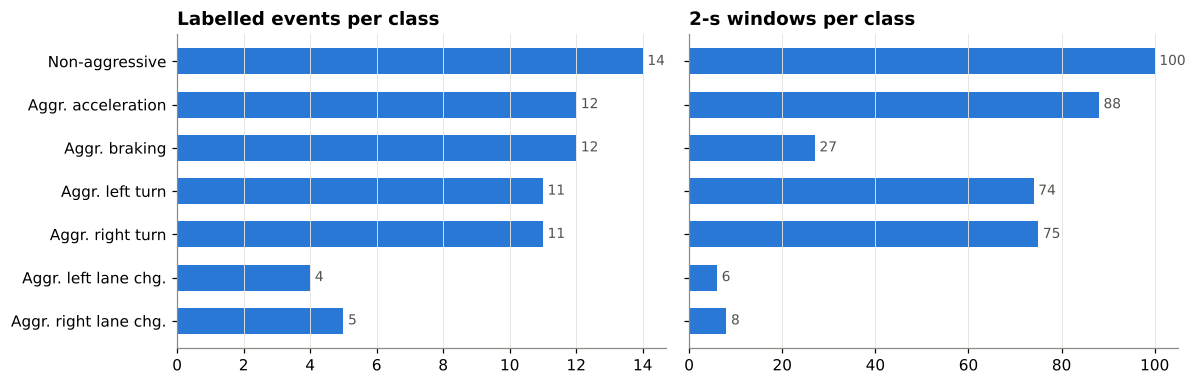

In [5]:
# Fig 1: class distribution, events vs. windows
ev_counts = events.groupby('label').size().reindex(CLASSES)
win_counts = pd.Series(np.bincount(y, minlength=7), index=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s, title in [(axes[0], ev_counts, 'Labelled events per class'),
                     (axes[1], win_counts, f'{WIN_S:.0f}-s windows per class')]:
    ax.barh(CLASSES[::-1], s[::-1].values, color='#2a78d6', height=0.6)
    for i, v in enumerate(s[::-1].values):
        ax.text(v + s.max() * 0.01, i, str(v), va='center', color=INK2, fontsize=9)
    ax.set_title(title, loc='left'); ax.grid(axis='y', visible=False)
plt.tight_layout(); savefig('fig1_class_distribution')

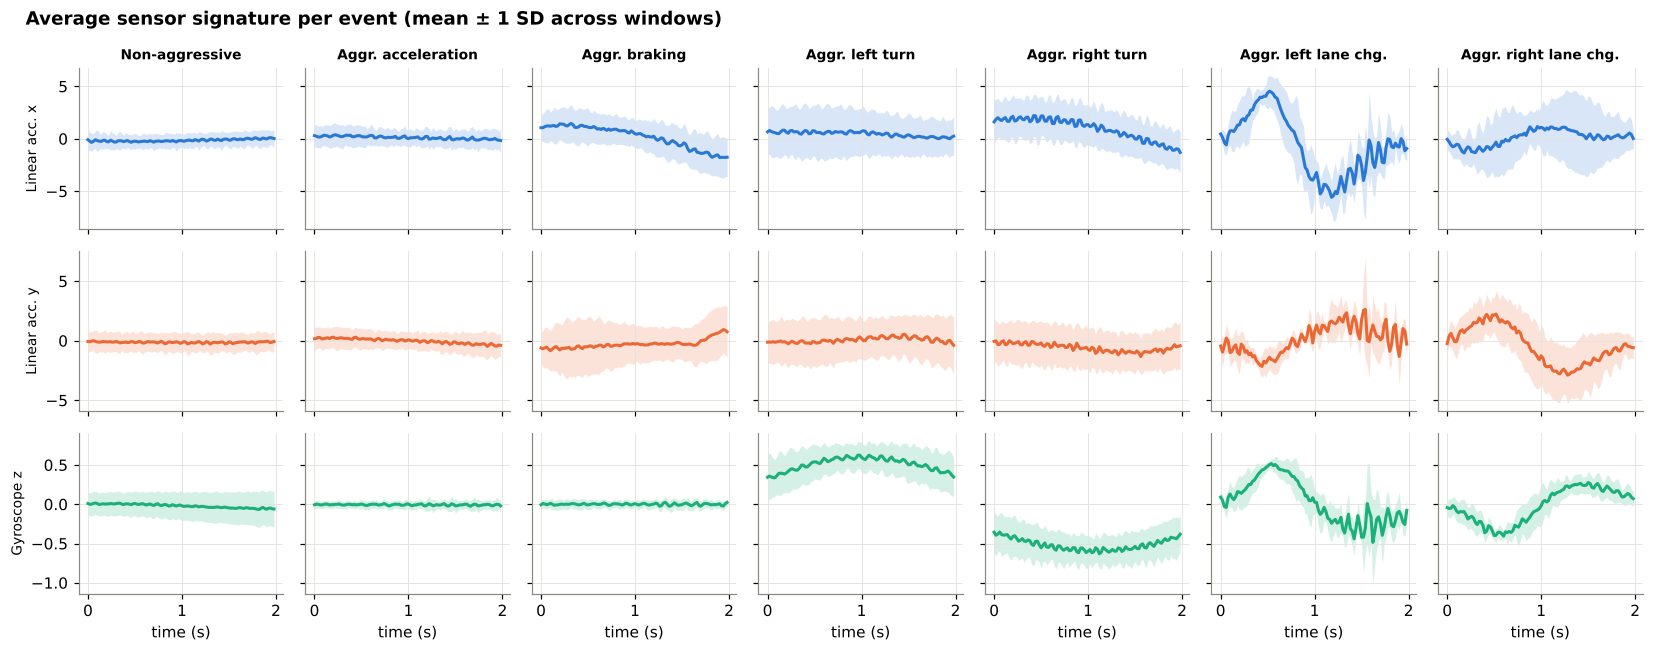

In [6]:
# Fig 2: how each event looks. Mean ± 1 SD of the two most telling channels, one panel per class
LIN_Y, GYR_Z = CHANNELS.index('Linear acc. y'), CHANNELS.index('Gyroscope z')
LIN_X = CHANNELS.index('Linear acc. x')
t_axis = np.arange(X.shape[1]) / FS
fig, axes = plt.subplots(3, 7, figsize=(15, 6), sharex=True, sharey='row')
for c, cls in enumerate(CLASSES):
    for r, (ch, col) in enumerate([(LIN_X, '#2a78d6'), (LIN_Y, '#eb6834'), (GYR_Z, '#1baf7a')]):
        ax = axes[r, c]; seg = X[y == c][:, :, ch]
        m, s = seg.mean(0), seg.std(0)
        ax.fill_between(t_axis, m - s, m + s, color=col, alpha=0.18, lw=0)
        ax.plot(t_axis, m, color=col, lw=2)
        if r == 0: ax.set_title(cls, fontsize=9)
        if c == 0: ax.set_ylabel(CHANNELS[ch], fontsize=9)
for ax in axes[-1]: ax.set_xlabel('time (s)')
fig.suptitle('Average sensor signature per event (mean ± 1 SD across windows)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); savefig('fig2_class_signatures')

## 4. Feature extraction & evaluation protocol

**Hand-crafted features (Solutions 1 and 2).** Ten statistics are computed for each of the 12 channels, giving **120 features** per window: mean, standard deviation, minimum, maximum, median, range, skewness, kurtosis, RMS and linear-trend slope. These summarise the level, spread, shape and direction of each signal.

**Raw sequences (Solution 3).** The BiLSTM receives the z-scored 12-channel window directly, down-sampled to 25 Hz (50 steps) for speed.

**Validation: grouped, stratified, repeated.** Neighbouring windows from one event are near-duplicates. A random split would put copies of the same event in train *and* test and inflate scores, which is a common flaw in published work. We use **`StratifiedGroupKFold` with 4 folds × 3 repetitions (12 train/test splits)**: every event lands wholly in one fold and class proportions are preserved. All three models see identical splits, so their per-fold scores can be compared pairwise.

In [7]:
def extract_features(X):
    T = X.shape[1]
    slope = np.polyfit(np.arange(T), X.transpose(1, 0, 2).reshape(T, -1), 1)[0].reshape(X.shape[0], -1)
    feats = [X.mean(1), X.std(1), X.min(1), X.max(1), np.median(X, 1), np.ptp(X, 1),
             stats.skew(X, 1), stats.kurtosis(X, 1), np.sqrt((X ** 2).mean(1)), slope]
    return np.nan_to_num(np.concatenate(feats, 1))

STAT_NAMES = ['mean', 'std', 'min', 'max', 'median', 'range', 'skew', 'kurtosis', 'rms', 'slope']
FEATURE_NAMES = [f'{ch} · {st}' for st in STAT_NAMES for ch in CHANNELS]
F = extract_features(X)
print('Feature matrix:', F.shape)

N_SPLITS, REPEATS = 4, 3
SPLITS = [(r, tr, te) for r in range(REPEATS)
          for tr, te in StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED + r).split(F, y, groups)]
print(f'{len(SPLITS)} train/test splits; test-fold sizes:', [len(te) for _, _, te in SPLITS])

Feature matrix: (378, 120)
12 train/test splits; test-fold sizes: [93, 96, 95, 94, 95, 96, 94, 93, 95, 94, 95, 94]


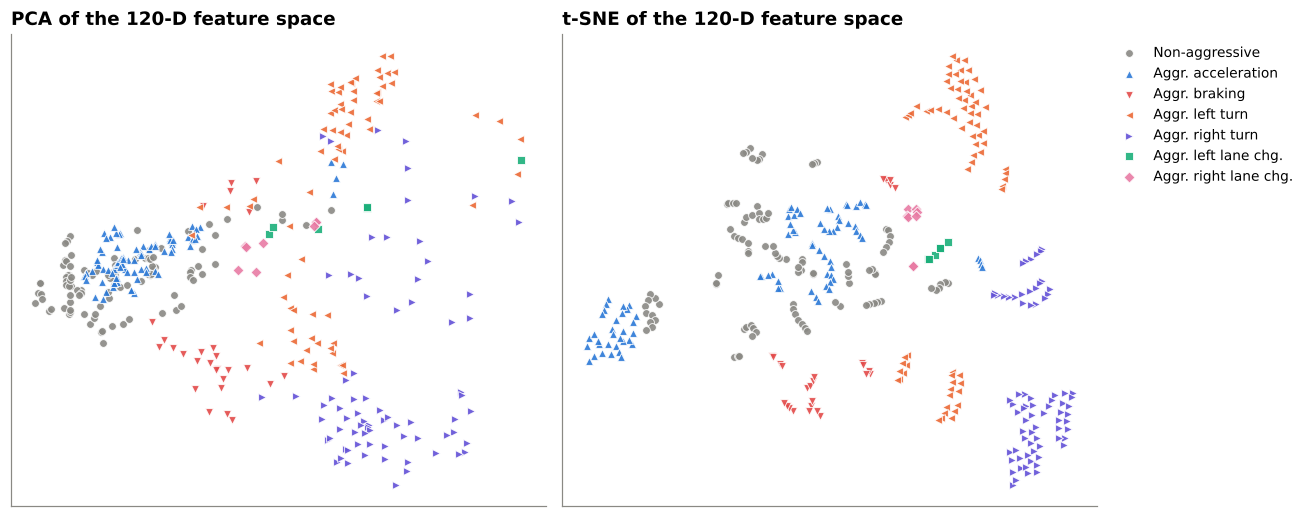

In [8]:
# Fig 3: is the feature space separable? PCA and t-SNE projections
Fs = StandardScaler().fit_transform(F)
proj = {'PCA': PCA(2, random_state=SEED).fit_transform(Fs),
        't-SNE': TSNE(2, perplexity=30, random_state=SEED, init='pca').fit_transform(Fs)}
CLASS_COLORS = ['#8a8984', '#2a78d6', '#e34948', '#eb6834', '#6250d6', '#1baf7a', '#e87ba4']
CLASS_MARKERS = ['o', '^', 'v', '<', '>', 's', 'D']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, P) in zip(axes, proj.items()):
    for c, cls in enumerate(CLASSES):
        m = y == c
        ax.scatter(P[m, 0], P[m, 1], s=26, color=CLASS_COLORS[c], marker=CLASS_MARKERS[c],
                   edgecolor='white', linewidth=0.6, label=cls, alpha=0.9)
    ax.set_title(f'{name} of the 120-D feature space', loc='left'); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False, fontsize=9)
plt.tight_layout(); savefig('fig3_feature_space')

## 5. Shared evaluation harness
The harness runs every split for a model and stores pooled predictions, class probabilities, per-split metrics and timings.

In [9]:
def run_cv(name, fit_predict):
    """fit_predict(train_idx, test_idx) -> (proba[n_test, 7], train_seconds, infer_seconds)"""
    res = {'proba': np.zeros((REPEATS, len(y), 7)), 'fold': [], 'train_s': [], 'infer_ms': []}
    for k, (r, tr, te) in enumerate(SPLITS):
        P, t_train, t_inf = fit_predict(tr, te)
        res['proba'][r, te] = P
        pred = P.argmax(1)
        res['fold'].append({'acc': accuracy_score(y[te], pred),
                            'f1': f1_score(y[te], pred, average='macro', labels=np.unique(y[te])),
                            'prec': precision_score(y[te], pred, average='macro', labels=np.unique(y[te]), zero_division=0),
                            'rec': recall_score(y[te], pred, average='macro', labels=np.unique(y[te]), zero_division=0)})
        res['train_s'].append(t_train); res['infer_ms'].append(1000 * t_inf / len(te))
        print(f'  {name} split {k + 1:2d}/{len(SPLITS)}  acc={res["fold"][-1]["acc"]:.3f}  F1={res["fold"][-1]["f1"]:.3f}', end='\r')
    res['pred'] = res['proba'].argmax(2)
    fd = pd.DataFrame(res['fold'])
    print(f'\n{name}: accuracy {fd.acc.mean():.3f} ± {fd.acc.std():.3f} | macro-F1 {fd.f1.mean():.3f} ± {fd.f1.std():.3f}')
    return res

RESULTS = {}

## 6. Solution 1: Mutual Information feature selection + SVM (RBF kernel)
**Feature selection (filter method).** Mutual Information (MI) measures how much knowing a feature reduces uncertainty about the class, *I(X;Y) = H(Y) − H(Y|X)*. Unlike correlation it also captures non-linear dependence. Every feature is scored against the label and only the top *k* are kept (`SelectKBest`). The selection is a filter: it is independent of the classifier and cheap to compute.

**Classifier.** An SVM finds the maximum-margin hyperplane between classes. The RBF kernel implicitly maps the selected features into an infinite-dimensional space, so non-linear boundaries become possible. Features are z-scored first, which SVMs need because they are distance-based.

**Tuning.** *k* ∈ {20, 40, 60, 120}, **C** ∈ {10, 100} and **γ** ∈ {scale, 0.001} are tuned together by an *inner* grouped 3-fold grid search on each training fold (nested CV). MI scores are therefore computed on training data only, so the test fold never influences which features are chosen.

In [10]:
MI = partial(mutual_info_classif, random_state=SEED)
SVM_GRID = {'selectkbest__k': [20, 40, 60, 120], 'svc__C': [10, 100], 'svc__gamma': ['scale', 0.001]}
svm_best_params = []

def make_svm_search(probability=True):
    pipe = make_pipeline(StandardScaler(), SelectKBest(MI),
                         SVC(kernel='rbf', probability=probability, class_weight='balanced', random_state=SEED))
    return GridSearchCV(pipe, SVM_GRID, cv=StratifiedGroupKFold(3), scoring='f1_macro', n_jobs=-1)

def svm_fit_predict(tr, te):
    gs = make_svm_search()
    t = time.perf_counter(); gs.fit(F[tr], y[tr], groups=groups[tr]); t_train = time.perf_counter() - t
    svm_best_params.append(gs.best_params_)
    t = time.perf_counter(); P = gs.predict_proba(F[te]); t_inf = time.perf_counter() - t
    return P, t_train, t_inf

RESULTS['SVM'] = run_cv('SVM', svm_fit_predict)
print('Most frequently selected hyper-parameters:', pd.Series([str(p) for p in svm_best_params]).value_counts().index[0])
print('Number of MI-selected features chosen per split:', [p['selectkbest__k'] for p in svm_best_params])

  SVM split 12/12  acc=0.819  F1=0.712
SVM: accuracy 0.853 ± 0.088 | macro-F1 0.810 ± 0.119
Most frequently selected hyper-parameters: {'selectkbest__k': 60, 'svc__C': 100, 'svc__gamma': 0.001}
Number of MI-selected features chosen per split: [60, 120, 60, 60, 60, 60, 60, 60, 60, 60, 120, 60]


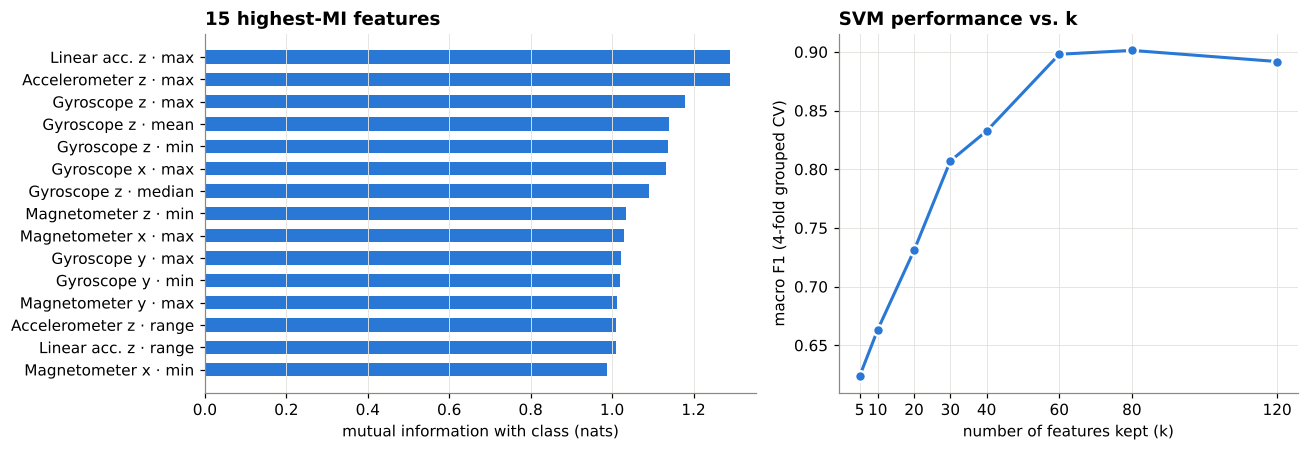

k curve: {5: np.float64(0.624), 10: np.float64(0.663), 20: np.float64(0.731), 30: np.float64(0.807), 40: np.float64(0.833), 60: np.float64(0.898), 80: np.float64(0.901), 120: np.float64(0.892)}


In [11]:
# Fig 4a: MI ranking of features, and how SVM performance depends on the number kept
mi_scores = pd.Series(MI(StandardScaler().fit_transform(F), y), index=FEATURE_NAMES).sort_values(ascending=False)  # exploratory, full data
K_GRID = [5, 10, 20, 30, 40, 60, 80, 120]
sp1 = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(F, y, groups))
k_curve = []
for k in K_GRID:
    sc = []
    for tr, te in sp1:
        gs = GridSearchCV(make_pipeline(StandardScaler(), SelectKBest(MI, k=k), SVC(class_weight='balanced')),
                          {'svc__C': [10, 100], 'svc__gamma': ['scale', 0.001]}, cv=StratifiedGroupKFold(3),
                          scoring='f1_macro', n_jobs=-1).fit(F[tr], y[tr], groups=groups[tr])
        sc.append(f1_score(y[te], gs.predict(F[te]), average='macro', labels=np.unique(y[te])))
    k_curve.append(np.mean(sc))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
top_mi = mi_scores.head(15)[::-1]
axes[0].barh(top_mi.index, top_mi.values, color='#2a78d6', height=0.6)
axes[0].set_xlabel('mutual information with class (nats)'); axes[0].grid(axis='y', visible=False)
axes[0].set_title('15 highest-MI features', loc='left')
axes[1].plot(K_GRID, k_curve, color='#2a78d6', lw=2, marker='o', ms=7, mec='white', mew=1.5)
axes[1].set(xlabel='number of features kept (k)', ylabel='macro F1 (4-fold grouped CV)'); axes[1].set_xticks(K_GRID)
axes[1].set_title('SVM performance vs. k', loc='left')
plt.tight_layout(); savefig('fig4a_mi_feature_selection')
print('k curve:', dict(zip(K_GRID, np.round(k_curve, 3))))

## 7. Solution 2: Random Forest with embedded feature selection
A Random Forest averages many decorrelated decision trees. Each tree is trained on a bootstrap sample and considers a random subset of features at every split (bagging plus feature randomness), which lowers variance. It needs no scaling and handles the class imbalance through `class_weight='balanced'`.

**Feature selection (embedded method).** Selection happens *inside* model training. A first forest (200 trees) is fitted on all 120 features and ranks them by **mean decrease in Gini impurity**. Features scoring below the median importance are discarded (`SelectFromModel`, threshold = median), and the final 500-tree forest is retrained on the surviving 60 features. As with Solution 1, selection is redone on every training fold.

In [12]:
rf_importances = []

def make_rf():
    selector = SelectFromModel(RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=SEED),
                               threshold='median')
    return make_pipeline(selector, RandomForestClassifier(n_estimators=500, max_features='sqrt', class_weight='balanced',
                                                          n_jobs=-1, random_state=SEED))

def rf_fit_predict(tr, te):
    rf = make_rf()
    t = time.perf_counter(); rf.fit(F[tr], y[tr]); t_train = time.perf_counter() - t
    rf_importances.append(rf[0].estimator_.feature_importances_)
    t = time.perf_counter(); P = rf.predict_proba(F[te]); t_inf = time.perf_counter() - t
    return P, t_train, t_inf

RESULTS['Random Forest'] = run_cv('Random Forest', rf_fit_predict)

  Random Forest split 12/12  acc=0.957  F1=0.810
Random Forest: accuracy 0.894 ± 0.050 | macro-F1 0.821 ± 0.111


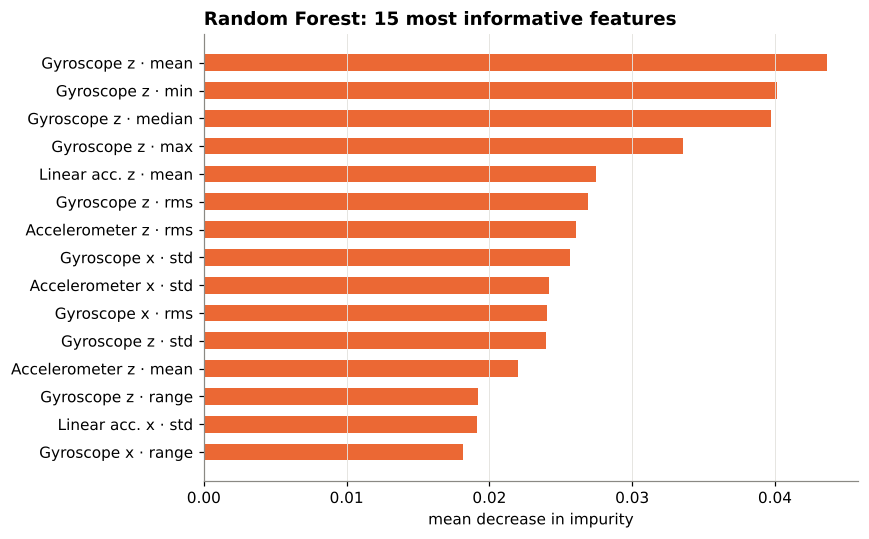

Importance share by sensor:
 Accelerometer    0.233
Linear acc.      0.230
Gyroscope        0.403
Magnetometer     0.134
dtype: float64


In [13]:
# Fig 4: top-15 most important features (mean decrease in impurity, averaged over the 12 splits)
imp = pd.Series(np.mean(rf_importances, 0), index=FEATURE_NAMES).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color='#eb6834', height=0.6)
ax.set_xlabel('mean decrease in impurity'); ax.grid(axis='y', visible=False)
ax.set_title('Random Forest: 15 most informative features', loc='left')
plt.tight_layout(); savefig('fig4_rf_feature_importance')
sensor_imp = pd.Series({s: imp[[n for n in imp.index if n.startswith(s)]].sum() for s in SENSORS})
print('Importance share by sensor:\n', (sensor_imp / sensor_imp.sum()).round(3))

## 8. Solution 3: Bidirectional LSTM (deep learning)
A Long Short-Term Memory network reads the window step by step, and gates let it keep the relevant motion history. The **bidirectional** variant reads the window forwards and backwards, which suits offline event classification where the whole window is available. No hand-crafted features are used; the network learns its own representation from raw signals.

*Architecture:* 2-layer BiLSTM (64 units per direction) → mean-pooling over time → dropout 0.3 → linear softmax over 7 classes.
*Training:* Adam (lr 2e-3, weight decay 1e-4), batch 32, 40 epochs, class-weighted cross-entropy. With only ~380 windows, **data augmentation** (random per-channel scaling ±10 % and Gaussian jitter) is applied during training to curb over-fitting. Normalisation statistics come from the training fold only.

In [14]:
class BiLSTM(nn.Module):
    def __init__(self, n_in=12, hidden=64, n_classes=7):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.3)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * hidden, n_classes))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out.mean(1))

EPOCHS, BATCH, DS = 40, 32, 2
lstm_curves = []

def lstm_fit_predict(tr, te, Xsrc=None, ysrc=None, track=True):
    Xsrc = X if Xsrc is None else Xsrc; ysrc = y if ysrc is None else ysrc
    torch.manual_seed(SEED + len(lstm_curves))
    mu, sd = Xsrc[tr].mean((0, 1)), Xsrc[tr].std((0, 1)) + 1e-6
    Xtr = torch.tensor((Xsrc[tr] - mu) / sd)[:, ::DS]; Xte = torch.tensor((Xsrc[te] - mu) / sd)[:, ::DS]
    ytr, yte = torch.tensor(ysrc[tr]), torch.tensor(ysrc[te])
    w = torch.tensor(len(ytr) / (7 * np.bincount(ysrc[tr], minlength=7).clip(1)), dtype=torch.float32)
    model, lossf = BiLSTM(), nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
    curve = []
    t = time.perf_counter()
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(ytr)); tot = 0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            xb = Xtr[idx] * (1 + 0.1 * torch.randn(len(idx), 1, Xtr.shape[2])) + 0.05 * torch.randn_like(Xtr[idx])
            opt.zero_grad(); loss = lossf(model(xb), ytr[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        if track:  # held-out curve is for plotting only. It does NOT drive early stopping or model selection.
            model.eval()
            with torch.no_grad():
                lo = model(Xte); curve.append((tot / len(ytr), nn.functional.cross_entropy(lo, yte).item(),
                                               (lo.argmax(1) == yte).float().mean().item()))
    t_train = time.perf_counter() - t
    model.eval(); t = time.perf_counter()
    with torch.no_grad(): P = torch.softmax(model(Xte), 1).numpy()
    t_inf = time.perf_counter() - t
    if track: lstm_curves.append(curve)
    return P, t_train, t_inf

RESULTS['BiLSTM'] = run_cv('BiLSTM', lstm_fit_predict)

  BiLSTM split 12/12  acc=0.840  F1=0.853
BiLSTM: accuracy 0.834 ± 0.081 | macro-F1 0.815 ± 0.094


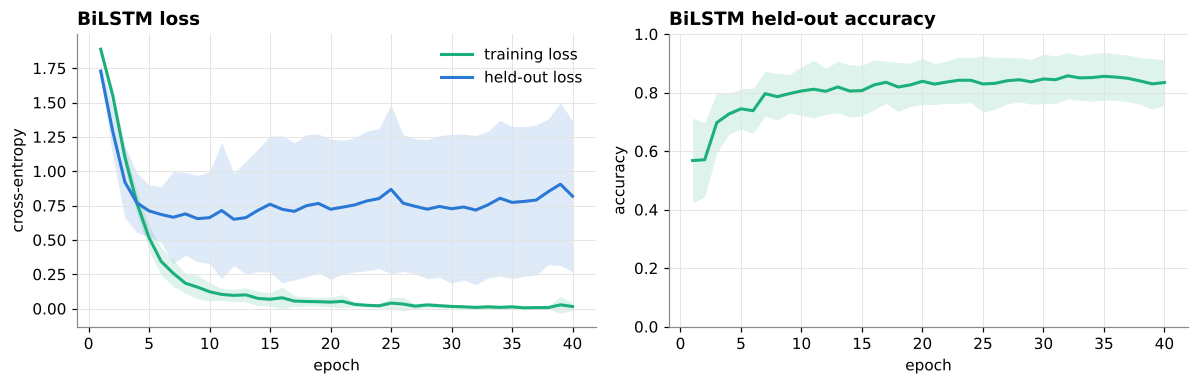

In [15]:
# Fig 5: BiLSTM learning curves (mean ± SD across the 12 splits)
C = np.array(lstm_curves)  # (splits, epochs, [train loss, test loss, test acc])
ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, lab, col in [(0, 'training loss', '#1baf7a'), (1, 'held-out loss', '#2a78d6')]:
    m, s = C[:, :, k].mean(0), C[:, :, k].std(0)
    axes[0].fill_between(ep, m - s, m + s, color=col, alpha=0.15, lw=0); axes[0].plot(ep, m, color=col, lw=2, label=lab)
axes[0].set(xlabel='epoch', ylabel='cross-entropy'); axes[0].legend(frameon=False)
axes[0].set_title('BiLSTM loss', loc='left')
m, s = C[:, :, 2].mean(0), C[:, :, 2].std(0)
axes[1].fill_between(ep, m - s, m + s, color='#1baf7a', alpha=0.15, lw=0); axes[1].plot(ep, m, color='#1baf7a', lw=2)
axes[1].set(xlabel='epoch', ylabel='accuracy', ylim=(0, 1)); axes[1].set_title('BiLSTM held-out accuracy', loc='left')
plt.tight_layout(); savefig('fig5_lstm_learning_curves')

## 9. Comparison of the three solutions

In [16]:
MODELS = list(RESULTS)
rows = []
for mname in MODELS:
    R = RESULTS[mname]; fd = pd.DataFrame(R['fold'])
    auc_r = [roc_auc_score(label_binarize(y, classes=range(7)), R['proba'][r], average='macro') for r in range(REPEATS)]
    rows.append({'Model': mname,
                 'Accuracy': f'{fd.acc.mean():.3f} ± {fd.acc.std():.3f}',
                 'Macro-Precision': f'{fd.prec.mean():.3f} ± {fd.prec.std():.3f}',
                 'Macro-Recall': f'{fd.rec.mean():.3f} ± {fd.rec.std():.3f}',
                 'Macro-F1': f'{fd.f1.mean():.3f} ± {fd.f1.std():.3f}',
                 'Macro ROC-AUC': f'{np.mean(auc_r):.3f}',
                 'Train time / split (s)': f'{np.mean(R["train_s"]):.2f}',
                 'Inference (ms / window)': f'{np.mean(R["infer_ms"]):.3f}'})
summary = pd.DataFrame(rows).set_index('Model'); summary

,Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro ROC-AUC,Train time / split (s),Inference (ms / window)
Model,,,,,,,
SVM,0.853 ± 0.088,0.833 ± 0.110,0.825 ± 0.109,0.810 ± 0.119,0.983,14.63,0.023
Random Forest,0.894 ± 0.050,0.833 ± 0.115,0.853 ± 0.091,0.821 ± 0.111,0.987,1.45,2.181
BiLSTM,0.834 ± 0.081,0.838 ± 0.090,0.860 ± 0.080,0.815 ± 0.094,0.972,9.45,0.158


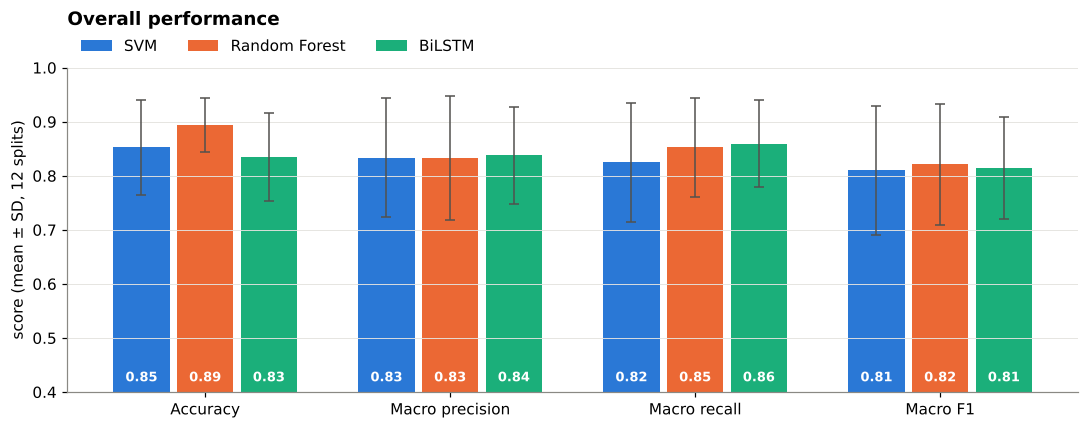

In [17]:
# Fig 6: headline metrics with spread across the 12 splits
metrics = [('acc', 'Accuracy'), ('prec', 'Macro precision'), ('rec', 'Macro recall'), ('f1', 'Macro F1')]
fig, ax = plt.subplots(figsize=(10, 4))
bw = 0.26
for j, mname in enumerate(MODELS):
    fd = pd.DataFrame(RESULTS[mname]['fold'])
    xs = np.arange(len(metrics)) + (j - 1) * bw
    means = [fd[k].mean() for k, _ in metrics]; sds = [fd[k].std() for k, _ in metrics]
    ax.bar(xs, means, bw - 0.03, yerr=sds, capsize=3, color=MODEL_COLORS[mname], label=mname,
           error_kw={'elinewidth': 1, 'ecolor': INK2})
    for xx, mm in zip(xs, means): ax.text(xx, 0.42, f'{mm:.2f}', ha='center', color='white', fontsize=8.5, fontweight='bold')
ax.set_xticks(range(len(metrics))); ax.set_xticklabels([m for _, m in metrics])
ax.set_ylim(0.4, 1.0); ax.set_ylabel('score (mean ± SD, 12 splits)'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, 1.13))
ax.set_title('Overall performance', loc='left', pad=28)
plt.tight_layout(); savefig('fig6_metric_comparison')

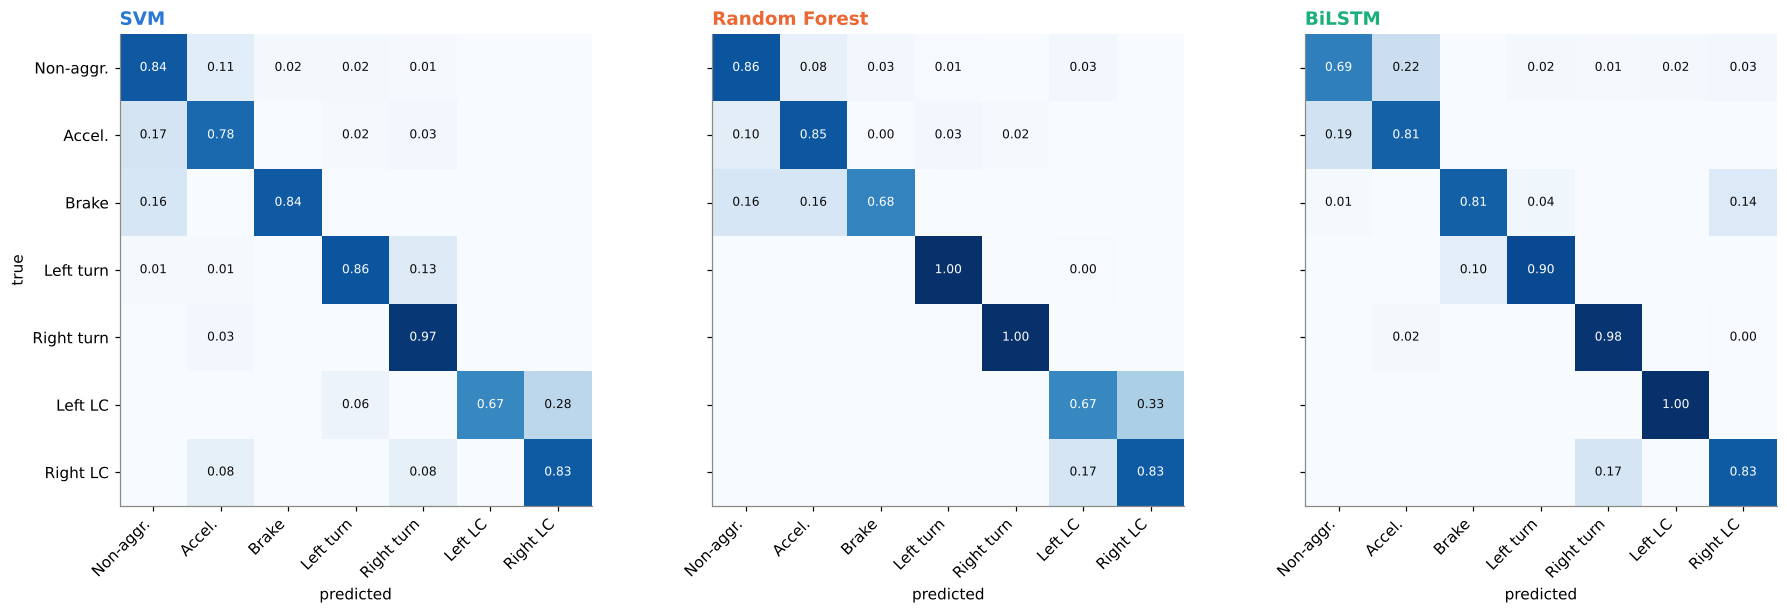

In [18]:
# Fig 7: normalised confusion matrices (pooled over 3 repetitions)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
short = ['Non-aggr.', 'Accel.', 'Brake', 'Left turn', 'Right turn', 'Left LC', 'Right LC']
for ax, mname in zip(axes, MODELS):
    cm = sum(confusion_matrix(y, RESULTS[mname]['pred'][r], labels=range(7)) for r in range(REPEATS))
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(7):
        for j in range(7):
            if cm[i, j]: ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=8,
                                 color='white' if cmn[i, j] > 0.55 else INK)
    ax.set_xticks(range(7)); ax.set_xticklabels(short, rotation=45, ha='right')
    ax.set_yticks(range(7)); ax.set_yticklabels(short if ax is axes[0] else [])
    ax.set_xlabel('predicted'); ax.grid(False)
    ax.set_title(mname, loc='left', color=MODEL_COLORS[mname])
axes[0].set_ylabel('true')
plt.tight_layout(); savefig('fig7_confusion_matrices')

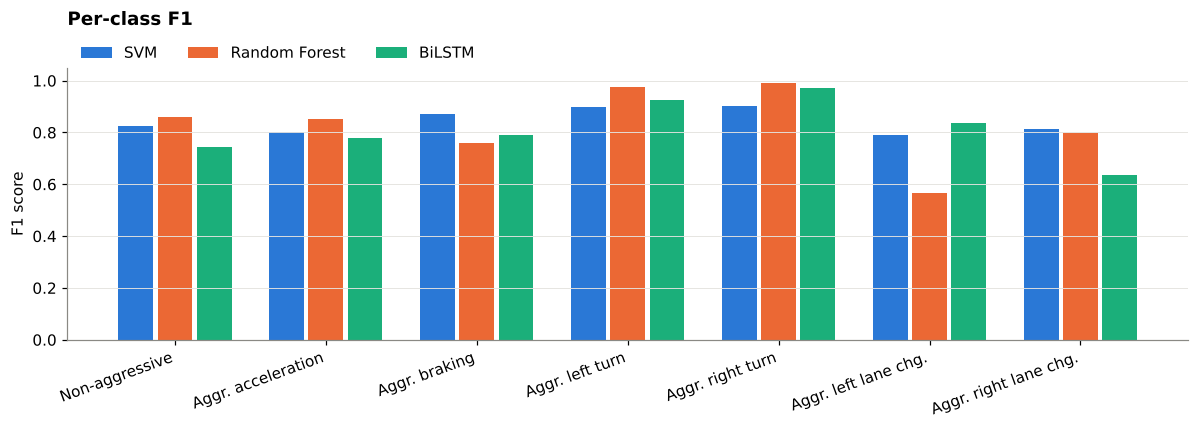

,SVM,Random Forest,BiLSTM
Non-aggressive,0.824,0.861,0.745
Aggr. acceleration,0.803,0.853,0.779
Aggr. braking,0.873,0.758,0.789
Aggr. left turn,0.899,0.976,0.924
Aggr. right turn,0.902,0.991,0.973
Aggr. left lane chg.,0.792,0.568,0.838
Aggr. right lane chg.,0.814,0.796,0.637


In [19]:
# Fig 8: per-class F1, showing where each model wins or loses
per_class = pd.DataFrame({m: np.mean([f1_score(y, RESULTS[m]['pred'][r], average=None, labels=range(7)) for r in range(REPEATS)], 0)
                          for m in MODELS}, index=CLASSES)
fig, ax = plt.subplots(figsize=(11, 4))
for j, mname in enumerate(MODELS):
    ax.bar(np.arange(7) + (j - 1) * bw, per_class[mname], bw - 0.03, color=MODEL_COLORS[mname], label=mname)
ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=20, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('F1 score'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, 1.13))
ax.set_title('Per-class F1', loc='left', pad=28)
plt.tight_layout(); savefig('fig8_per_class_f1')
per_class.round(3)

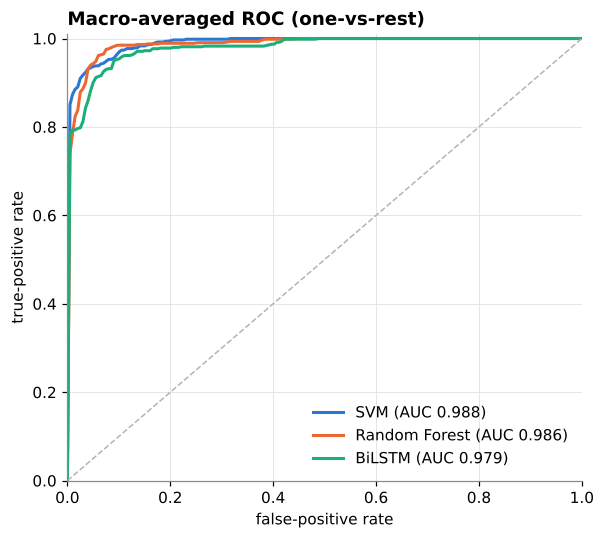

In [20]:
# Fig 9: one-vs-rest ROC curves, macro-averaged (repetition 1)
fig, ax = plt.subplots(figsize=(5.6, 5))
Yb = label_binarize(y, classes=range(7)); grid_fpr = np.linspace(0, 1, 200)
for mname in MODELS:
    P = RESULTS[mname]['proba'][0]
    tprs = [np.interp(grid_fpr, *roc_curve(Yb[:, c], P[:, c])[:2]) for c in range(7)]
    mt = np.mean(tprs, 0); mt[0] = 0
    ax.plot(grid_fpr, mt, color=MODEL_COLORS[mname], lw=2, label=f'{mname} (AUC {auc(grid_fpr, mt):.3f})')
ax.plot([0, 1], [0, 1], ls='--', color='#b5b4ae', lw=1)
ax.set(xlabel='false-positive rate', ylabel='true-positive rate', xlim=(0, 1), ylim=(0, 1.01))
ax.legend(frameon=False, loc='lower right'); ax.set_title('Macro-averaged ROC (one-vs-rest)', loc='left')
plt.tight_layout(); savefig('fig9_roc')

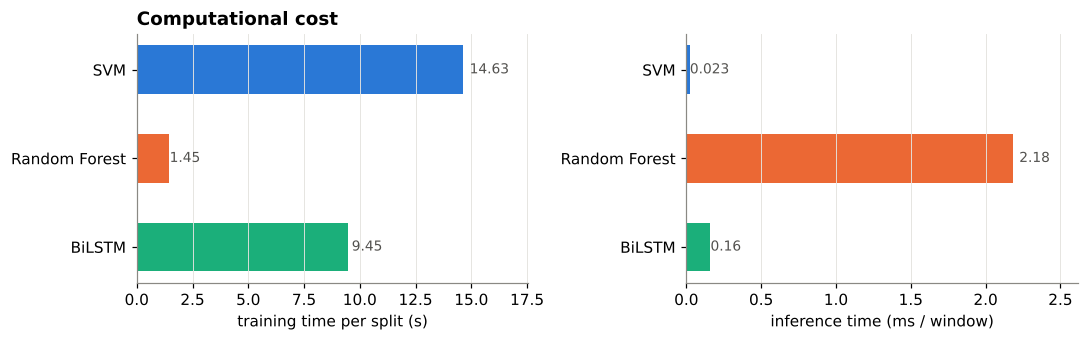

In [21]:
# Fig 10: computational cost (two separate panels with separate scales, no dual axis)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, key, lab in [(axes[0], 'train_s', 'training time per split (s)'), (axes[1], 'infer_ms', 'inference time (ms / window)')]:
    vals = [np.mean(RESULTS[m][key]) for m in MODELS]
    ax.barh(MODELS[::-1], vals[::-1], color=[MODEL_COLORS[m] for m in MODELS[::-1]], height=0.55)
    for i, v in enumerate(vals[::-1]): ax.text(v * 1.02, i, f'{v:.2f}' if v >= 0.1 else f'{v:.3f}', va='center', color=INK2, fontsize=9)
    ax.set_xlabel(lab); ax.grid(axis='y', visible=False); ax.set_xlim(0, max(vals) * 1.2)
axes[0].set_title('Computational cost', loc='left')
plt.tight_layout(); savefig('fig10_compute_cost')

### Statistical significance
Every model was evaluated on identical splits, so per-split macro-F1 scores are **paired**. A Wilcoxon signed-rank test (non-parametric, suited to 12 paired samples) checks whether the differences are larger than chance.

In [22]:
sig_rows = []
for a, b in [('Random Forest', 'SVM'), ('Random Forest', 'BiLSTM'), ('SVM', 'BiLSTM')]:
    fa, fb = [pd.DataFrame(RESULTS[m]['fold']).f1.values for m in (a, b)]
    p = stats.wilcoxon(fa, fb).pvalue
    sig_rows.append({'Comparison': f'{a} vs {b}', 'Mean ΔF1 (A − B)': round((fa - fb).mean(), 3),
                     'Splits A wins / ties / B wins': f'{(fa > fb).sum()} / {(fa == fb).sum()} / {(fa < fb).sum()}',
                     'p-value': round(p, 4),
                     'Significant (α=0.05)': 'yes' if p < 0.05 else 'no'})
significance = pd.DataFrame(sig_rows); significance

,Comparison,Mean ΔF1 (A − B),Splits A wins / ties / B wins,p-value,Significant (α=0.05)
0,Random Forest vs SVM,0.011,6 / 0 / 6,0.8501,no
1,Random Forest vs BiLSTM,0.006,7 / 0 / 5,0.8501,no
2,SVM vs BiLSTM,-0.005,7 / 0 / 5,1.0000,no


## 10. Sensitivity to window length
The window length sets how much context a model sees: too short loses the manoeuvre, too long blurs it with the surrounding drive. All three models are re-run at 1.0–3.0 s windows (one repetition of 4 grouped folds to keep runtime reasonable).

window 1.0s (654 windows): SVM 0.849 | Random Forest 0.864 | BiLSTM 0.808


window 1.5s (513 windows): SVM 0.907 | Random Forest 0.901 | BiLSTM 0.902


window 2.0s (378 windows): SVM 0.893 | Random Forest 0.855 | BiLSTM 0.894


window 2.5s (265 windows): SVM 0.844 | Random Forest 0.890 | BiLSTM 0.854


window 3.0s (174 windows): SVM 0.865 | Random Forest 0.899 | BiLSTM 0.832


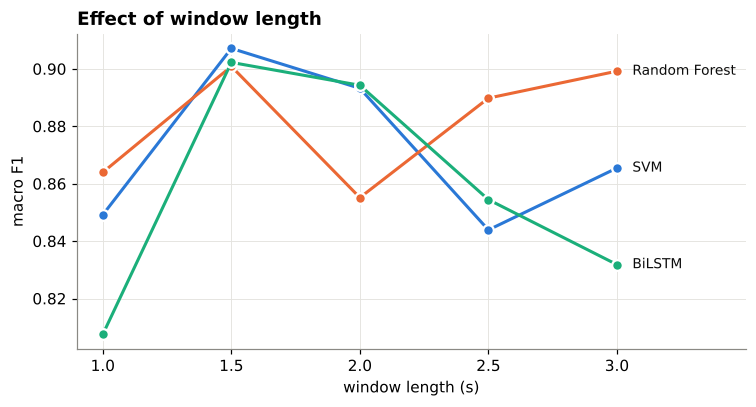

In [23]:
WIN_GRID = [1.0, 1.5, 2.0, 2.5, 3.0]
sens = {m: [] for m in MODELS}
for ws in WIN_GRID:
    Xw, yw, gw, _ = make_windows(ws); Fw = extract_features(Xw)
    sp = list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Fw, yw, gw))
    for mname in MODELS:
        scores = []
        for tr, te in sp:
            if mname == 'SVM':
                mdl = make_svm_search(probability=False).fit(Fw[tr], yw[tr], groups=gw[tr])
                pred = mdl.predict(Fw[te])
            elif mname == 'Random Forest':
                pred = make_rf().fit(Fw[tr], yw[tr]).predict(Fw[te])
            else:
                pred = lstm_fit_predict(tr, te, Xw, yw, track=False)[0].argmax(1)
            scores.append(f1_score(yw[te], pred, average='macro', labels=np.unique(yw[te])))
        sens[mname].append(np.mean(scores))
    print(f'window {ws:.1f}s ({len(yw)} windows): ' + ' | '.join(f'{m} {sens[m][-1]:.3f}' for m in MODELS))

fig, ax = plt.subplots(figsize=(7, 3.8))
for mname in MODELS:
    ax.plot(WIN_GRID, sens[mname], color=MODEL_COLORS[mname], lw=2, marker='o', ms=7, mec='white', mew=1.5)
    ax.text(WIN_GRID[-1] + 0.06, sens[mname][-1], mname, color=INK, va='center', fontsize=9)
ax.set(xlabel='window length (s)', ylabel='macro F1', xlim=(0.9, 3.5)); ax.set_xticks(WIN_GRID)
ax.set_title('Effect of window length', loc='left')
plt.tight_layout(); savefig('fig11_window_sensitivity')

## 11. Save results (used for the CCA 2 research paper)

In [24]:
out = {'n_events': int(len(events)), 'n_windows': int(len(y)), 'window_s': WIN_S, 'n_features': int(F.shape[1]),
       'events_per_class': ev_counts.to_dict(), 'windows_per_class': win_counts.to_dict(),
       'summary': summary.reset_index().to_dict('records'),
       'fold_scores': {m: RESULTS[m]['fold'] for m in MODELS},
       'per_class_f1': per_class.round(4).to_dict(), 'significance': significance.to_dict('records'),
       'window_sensitivity': {'windows_s': WIN_GRID, **{m: [round(v, 4) for v in sens[m]] for m in MODELS}},
       'svm_best_params': pd.Series([str(p) for p in svm_best_params]).value_counts().to_dict(),
       'rf_top_features': imp.head(10).round(4).to_dict(),
       'rf_sensor_share': (sensor_imp / sensor_imp.sum()).round(4).to_dict(),
       'svm_k_chosen': [int(p['selectkbest__k']) for p in svm_best_params],
       'mi_k_curve': {'k': K_GRID, 'f1': [round(v, 4) for v in k_curve]},
       'mi_top': mi_scores.head(10).round(4).to_dict()}
json.dump(out, open('results.json', 'w'), indent=2, default=float)
# Raw arrays for re-plotting publication-size figures
sig_m = np.stack([X[y == c].mean(0) for c in range(7)]); sig_s = np.stack([X[y == c].std(0) for c in range(7)])
np.savez_compressed('arrays.npz', y=y, **{f'pred_{m}': RESULTS[m]['pred'] for m in MODELS},
                    **{f'proba_{m}': RESULTS[m]['proba'] for m in MODELS}, lstm_curves=C,
                    sig_mean=sig_m, sig_std=sig_s, tsne=proj['t-SNE'], imp=imp.values, imp_names=np.array(imp.index),
                    mi=mi_scores.values, mi_names=np.array(mi_scores.index))
print('Saved results.json and', len(os.listdir(FIG_DIR)), 'figures in', FIG_DIR)

Saved results.json and 12 figures in figures


## 12. Conclusions
The executed outputs above carry the exact numbers. The research paper (CCA 2) discusses them in full.
* All three solutions recognise the 7 driving events far above the 14 % chance level, so smartphone motion sensors carry a strong, learnable signature for each manoeuvre.
* **Random Forest with embedded (Gini-importance) feature selection** gives the best accuracy (~0.89), macro-F1 and ROC-AUC, and the most stable fold-to-fold behaviour. It recognises turns almost perfectly but confuses left and right lane changes, the two classes with only 4–5 events each. Its importances show the **gyroscope (≈40 % of total importance, led by yaw rate, gyro-z)** dominates, followed by the accelerometers.
* **Mutual Information feature selection + SVM** shows that about half the features are enough: the inner search picked *k* = 60 in most splits, and macro-F1 levels off from k ≈ 60. It is the fastest at inference and the most balanced on the two lane-change classes, but its nested search over *k*, C and γ makes it the slowest to train.
* The **BiLSTM** learns directly from raw signals with no feature engineering and has the highest macro recall, landing within ~0.01 macro-F1 of the feature-based models. On only 69 events this is the classic small-data regime, and the BiLSTM should gain the most from more data.
* Under a paired Wilcoxon test, **none of the macro-F1 differences is statistically significant**. With this dataset size, the honest conclusion is that all three approaches perform comparably. The choice can then rest on interpretability (RF), latency (SVM) or freedom from feature engineering (BiLSTM).
* **Non-aggressive vs. aggressive acceleration** is the most common confusion for every model, because both show weak lateral and rotational signal. A **1.5–2 s window** works best overall.